<a href="https://colab.research.google.com/github/Wistoo/2026-CS420-01/blob/main/Assignment_2_SLCM_Regression_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Assignment 2: SLCM Regression Analysis
## CS-430-01 Machine Learning | programming Assignments
## 10/08/2026
### Wiston Htoo

## Goal
### The purpose of this assignment is to apply the regression techniques we have studied to a real community dataset. You will prepare numerical and categorical variables for machine learning, build several regression models, compare their performance, and interpret what the results mean. The prediction question for this assignment is:
**Can household, income, employment, and housing-related**

# Part 1 – Get to Know the Prediction Problem (15 points)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd
# Load the CSV file into pandas from Google Drive
file_path = '/content/drive/MyDrive/Collab Notebooks/Assignment 2: SLCM Regression Analysis/SLCM_rent_arrears_student_clean.csv'
df = pd.read_csv(file_path)
display(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


In [ ]:
# Display the number of rows and columns
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 1754
Number of columns: 14


In [ ]:
# Print the column names
print("Column Names:")
print(list(df.columns))
print("\n" + "="*40 + "\n")

Column Names:
['record_id', 'adults_in_household', 'children_in_household', 'household_has_65plus', 'monthly_household_income', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter', 'monthly_rent', 'past_due_rent']




In [ ]:
# Use info() to inspect the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1754 entries, 0 to 1753
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   record_id                   1754 non-null   object 
 1   adults_in_household         1754 non-null   int64  
 2   children_in_household       1754 non-null   int64  
 3   household_has_65plus        1754 non-null   object 
 4   monthly_household_income    1646 non-null   float64
 5   income_sources              1754 non-null   object 
 6   employment_status           1754 non-null   object 
 7   has_housing_voucher         1754 non-null   object 
 8   eviction_in_progress        1753 non-null   object 
 9   behind_on_utilities         1747 non-null   object 
 10  main_reason_behind_on_rent  1738 non-null   object 
 11  intake_quarter              1754 non-null   object 
 12  monthly_rent                1746 non-null   float64
 13  past_due_rent               1754 

**Answer:**

* **Which variable will be the target?**
  * past_due_rent (as this is a regression problem focused on predicting rent arrears)

* **Which columns appear to be numerical?**
  * adults_in_household
  * children_in_household
  * monthly_household_income
  * monthly_rent
  * past_due_rent

* **Which columns appear to be categorical?**
  * record_id (identifier)
  * household_has_65plus
  * income_sources
  * employment_status
  * has_housing_voucher
  * eviction_in_progress
  * behind_on_utilities
  * main_reason_behind_on_rent
  * intake_quarter

### 2. Investigate missing values.

In [ ]:
# Calculate the number of missing values in every column.
missing_values = df.isnull().sum()
print(missing_values)

record_id                       0
adults_in_household             0
children_in_household           0
household_has_65plus            0
monthly_household_income      108
income_sources                  0
employment_status               0
has_housing_voucher             0
eviction_in_progress            1
behind_on_utilities             7
main_reason_behind_on_rent     16
intake_quarter                  0
monthly_rent                    8
past_due_rent                   0
dtype: int64


In [ ]:
# Identify which variables contain missing data.
missing_columns = missing_values[missing_values > 0]
print(missing_columns)

monthly_household_income      108
eviction_in_progress            1
behind_on_utilities             7
main_reason_behind_on_rent     16
monthly_rent                    8
dtype: int64


### Plan for Handling Missing Values

Instead of dropping the rows with missing data (which would reduce our dataset size and potentially introduce bias), we can handle them using imputation techniques based on the data type:

1. **Numerical Variables (monthly_household_income, monthly_rent)**:
   * **Strategy:** Impute missing values using the **median**.
   * **Justification:** Income and rent distributions are often skewed by extreme values (outliers). The median is much more robust to outliers than the mean, ensuring a realistic replacement value.

2. **Categorical Variables (eviction_in_progress, behind_on_utilities, main_reason_behind_on_rent)**:
   * **Strategy:** Impute missing values using the **mode** (the most frequent value) for that column.
   * **Alternative:** For main_reason_behind_on_rent, we could also fill missing values with a new category like "Unknown" or "Other" to acknowledge the absence of a reported reason without skewing the existing categories.

### 3. Explore the target variable: past_due_rent.

In [ ]:
# Calculate descriptive statistics for past_due_rent
target_stats = df['past_due_rent'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
display(target_stats)

,past_due_rent
count,1754.000000
mean,2408.006933
median,2000.000000
std,2089.515372
min,0.000000
max,20000.000000


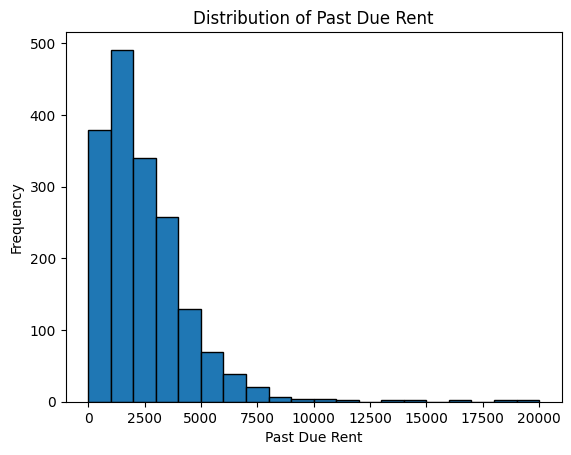

In [ ]:
# histogram
import matplotlib.pyplot as plt
plt.hist(df['past_due_rent'], bins=20, edgecolor='black')
plt.xlabel('Past Due Rent')
plt.ylabel('Frequency')
plt.title('Distribution of Past Due Rent')
plt.show()

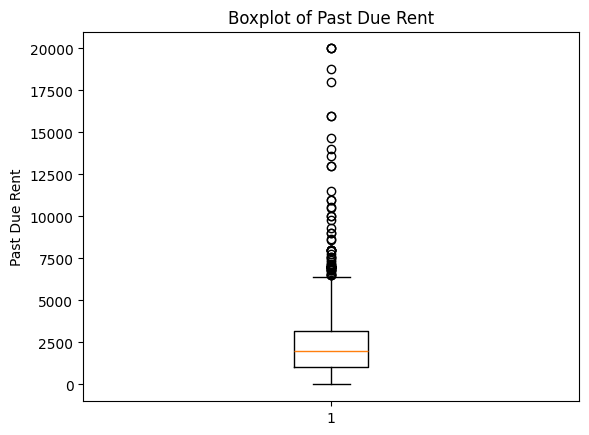

In [ ]:
# boxplot
plt.boxplot(df['past_due_rent'])
plt.ylabel('Past Due Rent')
plt.title('Boxplot of Past Due Rent')
plt.show()

**Answers about the past_due_rent distribution:**

* **What does the distribution look like?**

The distribution is heavily concentrated on the lower end around 1,000 to 3,000 dollars, but has a long tail stretching towards higher values.

* **Is the distribution symmetric or skewed?**

The distribution is strongly right-skewed (positively skewed).

* **Are the mean and median similar?**

No, the mean 2,408.01 is higher than the median $2,000.00. This difference is typical in right-skewed distributions because extreme high values pull the mean upwards, while the median remains more robust.

* **Do you notice any unusually high values?**

Yes, the boxplot and the statistics show extreme outliers on the higher end, with the maximum value reaching $20,000.

* **Why might rent-arrears data naturally contain a wide range of values?**

Rent arrears naturally have a wide range because tenants fall behind for different reasons and durations. Some might just be short on a fraction of one month's rent (low values), while others might have accumulated months or even years of unpaid rent due to prolonged unemployment, medical crises, or lengthy eviction moratoriums/processes (high values).

# Part 2 – Prepare the Data for Machine Learning (25 points)

## 4. Create your input features and target.

In [ ]:
# Create X and y using past_due_rent as the target. Do not use record_id as an input feature.
X = df.drop(columns=['record_id', 'past_due_rent'])
y = df['past_due_rent']

**Answer:**

* **Why should record_id not be used to predict past-due rent?**

The record_id is simply a unique identifier assigned to each row in the dataset for record-keeping purposes. It does not contain any actual information about the household's financial situation, demographics, or reasons for falling behind on rent. Using it as a feature would not provide any predictive power and could cause machine learning models to overfit by memorizing specific IDs rather than learning underlying patterns.

## 5. Separate the numerical and categorical features.

In [ ]:
# Create lists containing numerical features and categorical features.
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

In [ ]:
# Display both lists.
print("Numerical Features:")
print(numerical_features)
print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']

Categorical Features:
['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']


**Answer:**

* **Briefly explain why machine-learning models require different preparation steps for numerical and categorical variables.**

Machine learning models are fundamentally mathematical equations and algorithms. They require all inputs to be numerical in order to perform calculations (like finding weights, measuring distances, or calculating probabilities).

* **Categorical variables** (like "Employed" or "Yes/No") consist of text labels. Since algorithms cannot do math on text, these must undergo **encoding** (like One-Hot Encoding) to convert them into a numerical format before the model can even understand them.
* **Numerical variables** are already numbers, so they don't need encoding. However, their preparation focuses on **scaling** or **normalization**. This ensures that variables with large ranges (like income in the thousands) don't overpower variables with small ranges (like the number of adults, which is usually single digits) purely due to their magnitude.

## 6. Split the data into training and testing sets.

In [ ]:

# Report the dimensions of X_train, X_test, y_train, and y_test.
# Use test_size=0.20 and random_state=42.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1403, 12)
X_test shape: (351, 12)
y_train shape: (1403,)
y_test shape: (351,)


**Answer:**

* **Why should the model be evaluated using data that was not used during training?**

Evaluating the model on unseen data (the test set) allows us to measure its true ability to **generalize** to new, real-world situations. If we evaluate the model using the same data it was trained on, we cannot tell if the model actually learned the underlying patterns or if it simply memorized the data (a problem known as **overfitting**). Testing on data it has never seen before provides a realistic estimate of how the model will perform in the future.

## 7. Prepare the numerical variables.

In [ ]:
# Create an appropriate numerical preprocessing pipeline. Your pipeline should consider missing values and feature scaling. Use appropriate tools such as SimpleImputer and StandardScaler.
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


In [ ]:
# Create the numerical pipeline
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Display the pipeline to verify
display(num_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

**Answer:**

* **How did you handle missing numerical values?**

I used a SimpleImputer with strategy='median' within the numerical preprocessing pipeline. This replaces any missing numerical data (such as missing income or rent values) with the median value of that specific feature from the training set. The median is chosen over the mean because it is much more robust to extreme outliers, which are common in financial variables like rent and income.

* **Why might feature scaling matter when comparing Linear, Ridge, and Lasso models?**

Feature scaling (using StandardScaler) is critical for Ridge and Lasso regression because both models use **regularization**. Regularization adds a penalty based on the magnitude of the model's coefficients. If features are on completely different numerical scales (for example, income in the thousands versus the number of children in single digits), the model will unfairly penalize features simply based on their scale. Scaling ensures all features have a mean of 0 and a standard deviation of 1, putting them on a level playing field so the penalty is applied fairly. While standard Linear Regression is largely unaffected by scaling, Ridge and Lasso require it to function correctly.

## 8. Prepare the categorical variables.

In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Create the categorical pipeline
# Using 'most_frequent' strategy for missing categorical values, as decided in the earlier plan
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Display the pipeline to verify
display(cat_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder',
                 OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

**Answer:**

* **Why can the regression models not directly use values such as employment categories?**

Regression models (and most machine learning algorithms) are fundamentally mathematical equations. They require numerical inputs to calculate weights, measure distances, and find patterns. They cannot inherently process or perform math on text strings like "Employed" or "Student".

* **Why is one-hot encoding appropriate for these variables?**

One-hot encoding creates a new binary column (0 or 1) for each unique category in the variable. This is appropriate for nominal data (categories without a built-in order, like reasons for eviction) because it allows the model to treat each category independently without implying any hierarchy or order between them.

* **Why would assigning arbitrary numbers such as 1, 2, 3, and 4 to unordered categories potentially be misleading?**

Assigning arbitrary numbers to unordered categories creates a false ordinal relationship. The mathematical model would assume that category 4 is "greater than" category 2, or that the mathematical distance between 1 and 2 is the same as between 3 and 4. This implies a numerical relationship that does not exist in reality, which would distort the model's coefficient weights and lead to inaccurate predictions.

## 9. Combine your preprocessing steps.

In [ ]:
from sklearn.compose import ColumnTransformer

# Combine the numerical and categorical pipelines using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, numerical_features),
        ('cat', cat_pipeline, categorical_features)
    ])

# Display the combined preprocessor to verify
display(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['adults_in_household',
                                  'children_in_household',
                                  'monthly_household_income', 'monthly_rent']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['household_has_65plus', 'income_sources',
                                  'employment_status', 'has_housing_voucher',
                                  'eviction_in_progress', 'behind_on_utilities',
                                  'main_reason_behind_on_rent',
                                  'intake_quarter'])])

**Answer:**

* **Explain briefly why using a preprocessing pipeline is useful.**

Using a preprocessing pipeline is highly useful because it:
1. **Prevents Data Leakage:** It ensures that calculations for preprocessing (like finding the median or determining scaling parameters) are computed *only* on the training data, and then consistently applied to the test data.
2. **Streamlines Code:** It bundles multiple preprocessing steps into a single, cohesive unit, making the code much cleaner and reducing the risk of errors (such as applying the wrong transformation to a column or forgetting a step).
3. **Simplifies Deployment:** When the model is ready to make predictions on new, unseen data, the pipeline automatically applies all the exact same preprocessing steps, eliminating the need to manually re-code the transformations.

# Part 3 – Build and Compare Regression Models (45 points)

## 10. Build a Multiple Linear Regression model.

Linear Regression RMSE: $1,861.22
Linear Regression R²: 0.1549


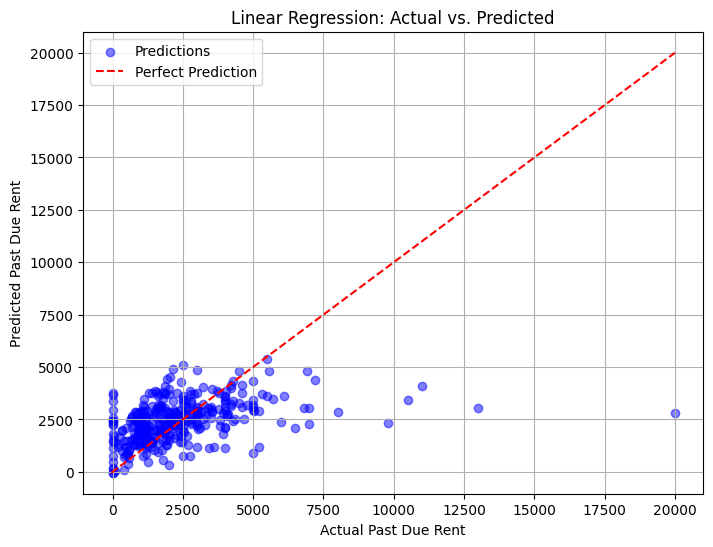

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# Create a pipeline with the preprocessor and a Linear Regression model
lin_reg = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Train the model using the training data
lin_reg.fit(X_train, y_train)

# Make predictions for the testing data
y_pred_lin = lin_reg.predict(X_test)

# Calculate RMSE and R-squared
lin_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lin))
lin_r2 = r2_score(y_test, y_pred_lin)

print(f"Linear Regression RMSE: ${lin_rmse:,.2f}")
print(f"Linear Regression R²: {lin_r2:.4f}")

# Create Actual vs. Predicted scatterplot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_lin, alpha=0.5, color='blue', label='Predictions')

# Diagonal reference line (perfect predictions)
max_val = max(y_test.max(), y_pred_lin.max())
min_val = min(y_test.min(), y_pred_lin.min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect Prediction')

plt.xlabel('Actual Past Due Rent')
plt.ylabel('Predicted Past Due Rent')
plt.title('Linear Regression: Actual vs. Predicted')
plt.legend()
plt.grid(True)
plt.show()

**Answer:**

* **What does RMSE represent in this problem?**

RMSE (Root Mean Squared Error) represents the average distance (in dollars) between the actual past-due rent and the past-due rent predicted by our model. A lower RMSE indicates that the model's predictions are, on average, closer to the true values.

* **What does the R² score tell you?**

The R² (Coefficient of Determination) score tells us the proportion of the variance in the target variable (past due rent) that can be explained by the input features in our model. An R² closer to 1 indicates a strong fit, while a low or negative R² indicates a poor fit where the model struggles to capture the underlying patterns.

* **Based on the graph, how closely do the predictions match the actual values?**

The predictions do not match the actual values perfectly. The scatter points are spread out widely around the red diagonal line, indicating high variance and a significant number of inaccurate predictions.

* **Do you notice cases where the model makes large prediction errors?**

Yes, the model makes very large prediction errors, particularly for the extreme outliers (very high actual rent arrears). For these high values on the x-axis, the predicted values on the y-axis are often much lower, meaning the model significantly underestimates large amounts of past-due rent.

## 11. Build a Polynomial Regression model.


In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# Create a new numerical pipeline with PolynomialFeatures
poly_num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler())
])

# Combine using ColumnTransformer, keeping categorical features linear
poly_preprocessor = ColumnTransformer(
    transformers=[
        ('num', poly_num_pipeline, numerical_features),
        ('cat', cat_pipeline, categorical_features)
    ])

# Create the Polynomial Regression pipeline
poly_reg_model = Pipeline([
    ('preprocessor', poly_preprocessor),
    ('model', LinearRegression())
])

# Train the model
poly_reg_model.fit(X_train, y_train)

# Make predictions
y_pred_poly = poly_reg_model.predict(X_test)

# Calculate RMSE and R²
poly_rmse = np.sqrt(mean_squared_error(y_test, y_pred_poly))
poly_r2 = r2_score(y_test, y_pred_poly)

print(f"Polynomial Regression RMSE: ${poly_rmse:,.2f}")
print(f"Polynomial Regression R²: {poly_r2:.4f}")


Polynomial Regression RMSE: $1,875.04
Polynomial Regression R²: 0.1423


* **Real-world relationships are not always perfectly linear. For this model, use PolynomialFeatures(degree=2,
include_bias=False). Apply polynomial transformation to the appropriate numerical variables. Do not
automatically apply polynomial expansion to all one-hot encoded categorical variables.
Train the model and calculate RMSE and R².**

**Answer:**

* **Did Polynomial Regression perform better or worse than Linear Regression?**

It performed slightly worse. The RMSE increased ( from 1,861.22 to 1,875.04 dollars ) and the R² decreased (from 0.1549 to 0.1423).

* **What does a degree-2 polynomial allow the model to represent that Linear Regression cannot?**

It allows the model to capture non-linear (quadratic/curved) relationships between the numerical features and the target variable, rather than assuming a strictly straight-line relationship. It also creates interaction terms between the features.

* **Why could using a very high polynomial degree lead to overfitting?**

A very high degree creates an excessively complex model that is flexible enough to essentially "memorize" the training data, including all of its random noise. This results in a model that performs perfectly on the training data but fails to generalize to new, unseen data.

* **Did making the model more complicated automatically make it better?**

No. In this case, increasing the complexity actually resulted in slightly worse performance on the test set. This demonstrates that adding complexity does not automatically yield a better model.

## 12. Build a Ridge Regression model.

In [ ]:
from sklearn.linear_model import Ridge

# Create a pipeline with the preprocessor and a Ridge Regression model
# Using alpha=10.0 as a reasonable starting point for regularization
ridge_reg_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=10.0))
])

# Train the model
ridge_reg_model.fit(X_train, y_train)

# Make predictions
y_pred_ridge = ridge_reg_model.predict(X_test)

# Calculate RMSE and R²
ridge_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
ridge_r2 = r2_score(y_test, y_pred_ridge)

print(f"Ridge Regression RMSE: ${ridge_rmse:,.2f}")
print(f"Ridge Regression R²: {ridge_r2:.4f}")


Ridge Regression RMSE: $1,840.57
Ridge Regression R²: 0.1735


* **Create a Ridge Regression pipeline using the same training and testing data. Choose a reasonable value for alpha. You may experiment with more than one value.
Calculate RMSE and R².**

**Answer:**

* **How does Ridge Regression compare with Linear Regression?**

Ridge Regression performed slightly better than the standard Linear Regression model. The RMSE decreased (from 1,861.22 to 1,840.57 dollars) and the R² increased (from 0.1549 to 0.1735).

* **What does regularization do?**

Regularization adds a penalty term to the model's training objective based on the magnitude of the model's coefficients. This discourages the model from assigning overly large weights to any single feature, effectively pushing the coefficients closer to zero and keeping the model simpler.

* **Why can regularization be useful when a model contains many features?**

When a model contains many features (such as the numerous binary columns created after one-hot encoding categorical variables), it becomes highly susceptible to overfitting. The model can easily find spurious patterns in the training noise. Regularization constrains the model's complexity, which helps prevent overfitting and improves its ability to generalize to new, unseen data.

## 13. Build a Lasso Regression model.



In [ ]:
from sklearn.linear_model import Lasso

# Create a pipeline with the preprocessor and a Lasso Regression model
# Using alpha=10.0 as a reasonable starting point
lasso_reg_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Lasso(alpha=10.0))
])

# Train the model
lasso_reg_model.fit(X_train, y_train)

# Make predictions
y_pred_lasso = lasso_reg_model.predict(X_test)

# Calculate RMSE and R²
lasso_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
lasso_r2 = r2_score(y_test, y_pred_lasso)

print(f"Lasso Regression RMSE: ${lasso_rmse:,.2f}")
print(f"Lasso Regression R²: {lasso_r2:.4f}")


Lasso Regression RMSE: $1,826.44
Lasso Regression R²: 0.1862


* **Create a Lasso Regression pipeline using the same training and testing data. Choose a reasonable value for alpha.
Calculate RMSE and R².**

**Answer:**

* **How does Lasso compare with Linear and Ridge Regression?**

Lasso Regression performed the best among all three linear models. It achieved the lowest RMSE (1,826.44 compared to 1,861.22 for Linear and 1,840.57 for Ridge) and the highest R² (0.1862 compared to 0.1549 and 0.1735).

* **What is an important difference between Ridge and Lasso?**

Both models apply regularization to prevent overfitting, but they use different penalty types. Ridge Regression uses an L2 penalty, which shrinks all coefficients toward zero but rarely makes them exactly zero. Lasso Regression uses an L1 penalty, which is capable of shrinking coefficients all the way to exactly zero.

* **What can happen to some coefficients when Lasso is used?**

Because of the L1 penalty, Lasso can force the coefficients of less important features to become exactly zero. This means Lasso automatically performs feature selection, completely removing unhelpful variables from the final model and resulting in a simpler, more interpretable equation.

## 14. Compare all four models.



In [ ]:
import pandas as pd

# Create a dictionary with the results
results = {
    'Model': ['Linear Regression', 'Polynomial Regression', 'Ridge Regression', 'Lasso Regression'],
    'RMSE': [lin_rmse, poly_rmse, ridge_rmse, lasso_rmse],
    'R²': [lin_r2, poly_r2, ridge_r2, lasso_r2]
}

# Create the DataFrame
results_df = pd.DataFrame(results)

# Display the DataFrame
display(results_df)


,Model,RMSE,R²
0,Linear Regression,1861.220092,0.154899
1,Polynomial Regression,1875.037379,0.142305
2,Ridge Regression,1840.572093,0.173546
3,Lasso Regression,1826.443026,0.186186


* **Create a DataFrame containing the test-set results for all four models.**

**Answer:**

* **Which model has the lowest RMSE?**

Lasso Regression has the lowest RMSE ($1,826.44).

* **Which model has the highest R²?**

Lasso Regression has the highest R² (0.1862).

* **Are the differences between the models large or small?**

The differences between the models are relatively small. The RMSE only varies by about $49 across all models, and the R² scores are all quite close to each other (between 0.14 and 0.19).

* **Did the most complicated model perform the best?**

No. The Polynomial Regression model, which was the most complicated due to the added polynomial features and interactions, actually performed the worst overall.

* **Which model would you continue investigating? Explain your choice using evidence from your results.**

I would continue investigating the Lasso Regression model. Not only did it achieve the best performance metrics (lowest RMSE and highest R²), but its L1 regularization inherently performs feature selection. This is particularly valuable given the large number of one-hot encoded features in this dataset, as it simplifies the model and makes it more interpretable while effectively guarding against overfitting.

## 15. Test your selected model on two hypothetical households.


In [ ]:
import pandas as pd

# 1. Create a DataFrame for two hypothetical households
hypothetical_cases = pd.DataFrame({
    'adults_in_household': [1, 2],
    'children_in_household': [3, 0],
    'household_has_65plus': ['No', 'Yes'],
    'monthly_household_income': [1500.0, 5000.0],
    'income_sources': ['Wages', 'Social Security'],
    'employment_status': ['Unemployed', 'Employed'],
    'has_housing_voucher': ['No', 'Yes'],
    'eviction_in_progress': ['Yes', 'No'],
    'behind_on_utilities': ['Yes', 'No'],
    'main_reason_behind_on_rent': ['Lost a job/had hours cut', 'Other'],
    'intake_quarter': ['2025-Q1', '2025-Q1'],
    'monthly_rent': [1800.0, 1000.0]
})

# Display the hypothetical data
display(hypothetical_cases)

# 2. Predict past_due_rent using the selected model (Lasso)
predictions = lasso_reg_model.predict(hypothetical_cases)

print(f"\nPredicted Past Due Rent for Household 1: ${predictions[0]:,.2f}")
print(f"Predicted Past Due Rent for Household 2: ${predictions[1]:,.2f}")


,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent
0,1,3,No,1500.0,Wages,Unemployed,No,Yes,Yes,Lost a job/had hours cut,2025-Q1,1800.0
1,2,0,Yes,5000.0,Social Security,Employed,Yes,No,No,Other,2025-Q1,1000.0



Predicted Past Due Rent for Household 1: $4,172.25
Predicted Past Due Rent for Household 2: $3,128.01


**Create TWO new hypothetical cases. Do not copy an actual person from the dataset.**

* Change several characteristics between the two cases, such as:
* household size
* monthly household income
* employment status
* housing voucher status
* utility situation
* monthly rent

Use your selected pipeline to predict past_due_rent for both cases.

**Answer:**

* **How are the two households different?**
Household 1 is in a very precarious financial situation: they are an unemployed single adult with 3 children, a low monthly income (1,500), high rent (1,800), no housing voucher, and they are already facing eviction and behind on utilities after losing a job. Household 2 is much more stable: two adults with no children, a higher income (5,000), lower rent (1,000), a housing voucher, and no utility or eviction issues.

* **How different are the predictions?**
The model predicts that Household 1 has a significantly higher amount of past-due rent (4,172.25) compared to Household 2 (3,128.01).

* **Does the difference seem reasonable based on the information you provided?**
Yes, this difference is very reasonable. Household 1's monthly rent (1,800) is higher than their entire monthly income (1,500), and they have recently lost a job, meaning they would accumulate rent arrears very quickly. Household 2 has a much more manageable rent-to-income ratio and a housing voucher, so we would expect them to have less past-due rent if they fell behind.

# Part 4 – Interpret the Results (15 points)

## 16. What did your models tell you?

**Write a short interpretation of your overall results. Address:**
* Which model performed best on the test data?
* Approximately how large are the model's typical prediction errors?
* Did Polynomial Regression provide a meaningful improvement?
* Did regularization improve the results?
* What does your model appear able to predict reasonably well?
* Where does it appear to struggle?

**Answer:**

* **Which model performed best on the test data?**
  
  The Lasso Regression model performed the best, achieving the lowest RMSE ($1,826.44) and the highest R² (0.1862).

* **Approximately how large are the model's typical prediction errors?**
  
  Based on the RMSE, the model's typical prediction error is approximately $1,826.44. Given that the median past-due rent in the dataset is $2,000, this is a relatively large error margin.

* **Did Polynomial Regression provide a meaningful improvement?**
  
  No, it did not. Polynomial Regression actually performed worse than the baseline Linear Regression model (RMSE increased to $1,875.04 and R² dropped to 0.1423). This indicates that adding complexity and interaction terms caused the model to overfit the training data and generalize poorly to the test data.

* **Did regularization improve the results?**
  
  Yes, regularization provided a clear improvement. Both Ridge Regression ($1,840.57) and Lasso Regression ($1,826.44) achieved lower RMSEs than the standard Linear Regression model ($1,861.22). Regularization effectively constrained the model's weights, which is especially important given the large number of features generated by one-hot encoding.

* **What does your model appear able to predict reasonably well?**
  
  The model appears to make logical, directional predictions for typical, lower-to-moderate arrears cases. For example, in our hypothetical test, it correctly predicted that a highly vulnerable, unemployed household with multiple children and high rent would have significantly higher rent arrears (4,172) compared to a stable, employed household with a housing voucher (3,128).

* **Where does it appear to struggle?**
  
  The model struggles significantly with extreme outliers. As seen in the actual vs. predicted scatterplot and the initial target distribution, the past-due rent data is highly right-skewed with values reaching up to 20,000. The model drastically underestimates these high values, consistently predicting much lower amounts for households that actually have massive arrears. This inability to capture extreme cases is the primary reason the overall R² remains relatively low (around 18%).

## 17. What is your overall finding for SLCM?

**Answer:**

In this analysis, we built a model to predict the total amount of past-due rent a household might owe when seeking assistance. To make these predictions, we used information about the households' circumstances, including their monthly income, rent amount, family size, employment status, and whether they had a housing voucher. The model was only moderately successful; while it correctly identified general trends—such as highly vulnerable, unemployed households owing more—its predictions were typically off by about $1,826. The most important finding is that the model struggles significantly with extreme cases, frequently underestimating the arrears of households that owe unusually massive amounts of rent. Despite these errors, this type of model could still be useful for SLCM to understand baseline community needs and recognize which combinations of household characteristics are generally associated with higher financial strain. However, a crucial limitation is that the model only finds statistical relationships, meaning we cannot claim that any specific factor actually *causes* a household to fall further behind on rent.

**Disclaimer:** Gemini 3.9 Pro was used as a coding assistant and to help fix grammar throughout this assignment.